Business problem:
The company wants to know whether the relationship between employee experience and salary is better represented by a non-linear relationship rather than a straight line.Building a Polynomial Regression model that predicts employee salary based on years of experience while allowing for a non-linear relationship between experience and salary.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv(r"Downloads/archive (7)/employee_performance.csv")

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1020 entries, 0 to 1019
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Employee_ID        1020 non-null   object 
 1   Age                1020 non-null   int64  
 2   Gender             1020 non-null   object 
 3   Department         1020 non-null   object 
 4   Experience_Years   988 non-null    float64
 5   Performance_Score  990 non-null    float64
 6   Salary             1020 non-null   int64  
dtypes: float64(2), int64(2), object(3)
memory usage: 55.9+ KB


In [5]:
df.describe()

,Age,Experience_Years,Performance_Score,Salary
count,1020.000000,988.000000,990.000000,1020.000000
mean,40.898039,7.209919,69.755657,52905.790196
std,11.160063,3.070575,9.935075,33016.717394
min,22.000000,0.000000,37.600000,5000.000000
25%,31.000000,5.200000,63.025000,38867.750000
50%,42.000000,7.250000,70.050000,50595.500000
75%,50.000000,9.200000,76.675000,60984.250000
max,59.000000,16.800000,97.500000,400000.000000


In [65]:
df['Experience_Years'] = df['Experience_Years'].fillna(df['Experience_Years'].median())
df['Performance_Score'].fillna(df['Performance_Score'].median(),inplace=True)

C:\Users\hp\AppData\Local\Temp\ipykernel_5560\701672766.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Performance_Score'].fillna(df['Performance_Score'].median(),inplace=True)


In [66]:
df = df.drop_duplicates()

In [67]:
df.shape

(985, 7)

In [68]:
Q1 = df['Salary'].quantile(0.25)
Q3 = df['Salary'].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Limit:", lower_limit)
print("Upper Limit:", upper_limit)


Q1: 38758.0
Q3: 60697.0
IQR: 21939.0
Lower Limit: 5849.5
Upper Limit: 93605.5


In [69]:
salary_outliers = df[(df['Salary'] < lower_limit) |(df['Salary'] > upper_limit)]
print(salary_outliers)
print("Number of outliers:", len(salary_outliers))

Empty DataFrame
Columns: [Employee_ID, Age, Gender, Department, Experience_Years, Performance_Score, Salary]
Index: []
Number of outliers: 0


In [70]:
df = df[(df['Salary'] >= lower_limit) &(df['Salary'] <= upper_limit)]

In [71]:
df.shape

(985, 7)

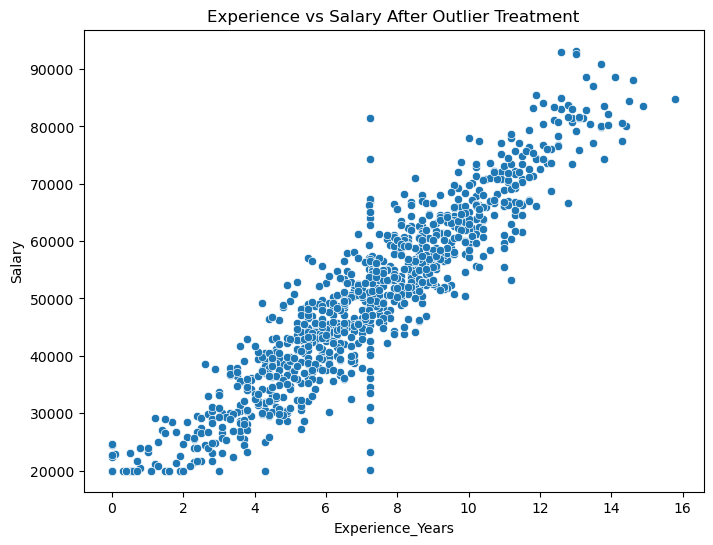

In [72]:
plt.figure(figsize=(8,6))
sns.scatterplot(data=df,x='Experience_Years',y='Salary')
plt.xlabel('Experience_Years')
plt.ylabel('Salary')
plt.title('Experience vs Salary After Outlier Treatment')
plt.show()

In [73]:
df[['Experience_Years', 'Salary','Age']].corr()

,Experience_Years,Salary,Age
Experience_Years,1.000000,0.927505,0.016935
Salary,0.927505,1.000000,0.034501
Age,0.016935,0.034501,1.000000


In [74]:
X = df[['Experience_Years','Performance_Score','Age']]
y = df['Salary']

In [75]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y,test_size=0.3,random_state=42)

In [77]:
#basic model
from sklearn.preprocessing import PolynomialFeatures
polynomial_convertor=PolynomialFeatures(degree=2,include_bias=False)
X_train=pd.DataFrame(polynomial_convertor.fit_transform(X_train))
X_test=pd.DataFrame(polynomial_convertor.transform(X_test))
x_poly=polynomial_convertor.fit_transform(X)
x_poly=pd.DataFrame(x_poly)
#x_poly=pd.DataFrame(polynomial_convertor.fit_transform(x))

In [81]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

In [82]:
model.intercept_
model.coef_

array([ 1.68781444e+04,  7.30602689e+03,  1.12986597e+03,  1.72659638e+02,
       -2.64319446e+02, -8.53413087e+01, -7.68590138e+01,  6.21408836e+00,
       -2.64482351e+01,  1.72659641e+02, -2.64319451e+02, -8.53413108e+01,
       -4.71026239e+01,  7.30292643e+00, -8.13205430e+00,  2.62513999e+00,
        9.86240243e-01,  2.35792240e+00, -7.68590113e+01,  6.21408856e+00,
        7.30292899e+00,  2.62513884e+00,  9.86240263e-01,  1.14219791e+00,
        7.52659210e-01, -1.22581159e+00, -2.64482376e+01, -8.13205445e+00,
        9.86240323e-01,  2.35792233e+00,  7.52659575e-01, -1.22581174e+00,
        1.73516050e+00,  1.73897492e+00, -8.22718027e-02, -2.00522172e-01,
       -5.31422510e-02,  3.31453491e-02,  1.04057075e-01, -5.31383046e-02,
        3.31457604e-02, -8.69278184e-03, -2.11800411e-02,  1.45236106e-02,
        1.04057325e-01, -2.11907998e-02,  1.45257051e-02, -7.79300640e-02,
       -3.56512390e-03, -3.89017876e-03, -4.14361122e-03, -4.19364223e-03,
        2.51622587e-02, -

In [83]:
test_pred=model.predict(X_test)
train_pred=model.predict(X_train)

In [85]:
model.score(X_train,y_train)

0.8838470563737756

In [86]:
model.score(X_test,y_test)

0.8749560801486062

In [87]:
from sklearn.model_selection import cross_val_score
score = cross_val_score(model,x_poly,y,cv=5)
score.mean()

0.8779415875330615

In [90]:
#hyper parameter tunning
train_r2 = []
test_r2 = []

from sklearn.preprocessing import PolynomialFeatures
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
import pandas as pd

for i in range(1, 10):

    polynomial_converter = PolynomialFeatures(
        degree=i,
        include_bias=False
    )

    x_poly = polynomial_converter.fit_transform(X)

    X_train, X_test, y_train, y_test = train_test_split(
        x_poly, y,
        test_size=0.3,
        random_state=42
    )

    model = LinearRegression()
    model.fit(X_train, y_train)

    # R² scores
    test_r2.append(model.score(X_test, y_test))
    train_r2.append(model.score(X_train, y_train))

In [91]:
print(train_r2)

[0.874776062685477, 0.8779764590633329, 0.8818303783972881, 0.8838470563737759, 0.8881095375776835, 0.8935941085644319, 0.8981065499831616, 0.8997459013535434, 0.9073579416947178]


In [92]:
print(test_r2)

[0.8842283590008089, 0.8836055824033902, 0.8801139952631769, 0.8749560802495131, 0.8698872091713471, 0.8495591156354418, 0.7624175167764293, -0.2789364349807213, -23.14763537429595]


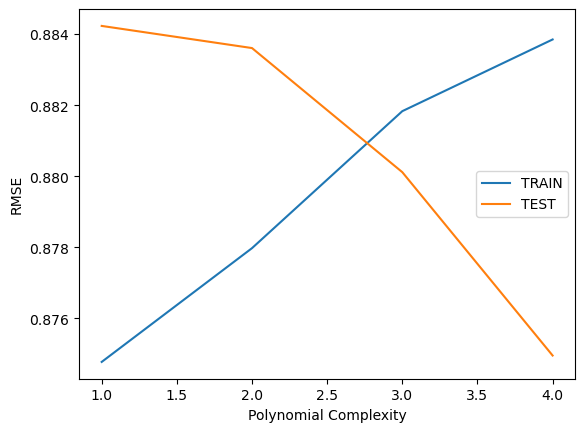

In [93]:
plt.plot(range(1, 5), train_r2[:4], label="TRAIN")
plt.plot(range(1, 5), test_r2[:4], label="TEST")
plt.xlabel("Polynomial Complexity")
plt.ylabel("RMSE")
plt.legend()
plt.show()

In [94]:
final_poly_converter = PolynomialFeatures(
    degree=3,
    include_bias=False
)

x_poly = final_poly_converter.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(
    x_poly, y,
    test_size=0.3,
    random_state=42
)

final_model = LinearRegression()
final_model.fit(X_train, y_train)

train_pred = final_model.predict(X_train)
test_pred = final_model.predict(X_test)

print("Train R2:", final_model.score(X_train, y_train))
print("Test R2:", final_model.score(X_test, y_test))

Train R2: 0.8818303783972881
Test R2: 0.8801139952631769


In [95]:
new_data = [[25, 5, 80]]   # example only

new_data_poly = final_poly_converter.transform(new_data)

prediction = final_model.predict(new_data_poly)

print("Predicted value:", prediction[0])

Predicted value: 71618.17377497577


C:\ProgramData\anaconda3\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(
